# BGC-Argo POC flux distribution: all depths in one model (step 4)

| Step | Content | Status |
|---|---|---|
| 0–2 | Source data, raw distributions, data cleaning (`step0-2_data_cleaning.ipynb`) | Done |
| 3 | Fit the model per depth (`step3_fit_model.ipynb`) | Done |
| 4 | Fit all depths together and compare with Edwards et al. 2026 | Done |

## Step 4: All depths in one model

**Aim:** Fit one model to the four depths together, with depth as a predictor as in Edwards et al. (2026), and compare the result with their reported numbers.

```
ln F ~ Normal(mu, sigma)
mu       = b0 + b1 T + b2 C + b3 Z + b4 T C + b5 T Z + b6 C Z
ln sigma = g0 + g1 T + g2 C + g3 Z + g4 T C + g5 T Z + g6 C Z
T = ln(SST + 2), C = ln(Chl-a), Z = ln(depth), each standardized
```

Differences from Edwards et al.: ln σ instead of σ is linear in the predictors, weakly informative priors, SST + 2 instead of SST + 1.79, and same-day instead of monthly SST and Chl-a. F is converted to mg C so the axes match theirs.

In [1]:
import logging
import warnings
from pathlib import Path

import cmdstanpy
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from cmcrameri import cm
from scipy.stats import ks_2samp, pearsonr

cmdstanpy.utils.get_logger().setLevel(logging.ERROR)   # hide sampler progress
warnings.filterwarnings("ignore", message=".*matmul.*")   # spurious on macOS; results are checked to be finite below

BASE = Path("/Volumes/T7/BGC-Argo-try/BGC-Argo-1/OneArgo-R/Tutorial_101/Codes/1_Core folder")
PROJ = BASE / "1_Result/1104_bayes_perdepth_project"
TERMS = ["intercept", "T", "C", "Z", "T x C", "T x Z", "C x Z"]

clean = pd.read_csv(PROJ / "cleaned_data.csv")
y = np.log(clean["F_5_12"].values * 12.011)   # mg C m-2 d-1

standardize = lambda a: (a - a.mean()) / a.std()
raw = {"T": np.log(clean["sst_day"].values + 2), "C": np.log(clean["chl_day"].values), "Z": np.log(clean["depth"].values)}
T, C, Z = (standardize(raw[k]) for k in "TCZ")
x = np.column_stack([np.ones(len(y)), T, C, Z, T * C, T * Z, C * Z])
print("n =", len(y), "| SD of T, C, Z:", {k: round(v.std(), 3) for k, v in raw.items()})

/Users/yucandong/Library/Python/3.10/lib/python/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


n = 296122 | SD of T, C, Z: {'T': np.float64(0.718), 'C': np.float64(0.797), 'Z': np.float64(0.841)}


In [2]:
model = cmdstanpy.CmdStanModel(stan_file=BASE / "1_Script/perdepth_lognormal_v3_1103.stan")
fit = model.sample(data=dict(N=len(y), p=x.shape[1], y=y, x=x), chains=4, parallel_chains=4, seed=4,
                   iter_warmup=1000, iter_sampling=1000, adapt_delta=0.9, show_progress=False)
beta, gamma = fit.stan_variable("beta"), fit.stan_variable("gamma")
np.savez(PROJ / "fits/draws_pooled.npz", beta=beta, gamma=gamma)

s = fit.summary()
s = s[s.index.str.startswith(("beta", "gamma"))][["Mean", "StdDev", "R_hat", "ESS_bulk", "ESS_tail"]]
s.index = [f"mu: {t}" for t in TERMS] + [f"ln sigma: {t}" for t in TERMS]
print("divergent transitions:", int(fit.method_variables()["divergent__"].sum()))
s.round(3)

divergent transitions: 0


,Mean,StdDev,R_hat,ESS_bulk,ESS_tail
mu: intercept,3.640,0.001,1.000,5597.32,3396.12
mu: T,0.042,0.001,1.001,5012.19,3365.41
mu: C,0.095,0.001,1.000,5550.55,3301.50
mu: Z,-0.726,0.001,1.003,6025.39,2680.87
mu: T x C,0.011,0.001,1.000,5102.88,3346.89
mu: T x Z,0.004,0.001,1.000,4602.56,3155.53
mu: C x Z,0.054,0.001,1.001,4338.39,3155.50
ln sigma: intercept,-0.868,0.001,1.000,3555.37,2814.45
ln sigma: T,-0.048,0.001,1.002,3405.79,2175.00
ln sigma: C,0.082,0.001,1.001,3306.34,2644.12


In [3]:
# Generated values as in Edwards et al.: posterior mean mu and sigma, one random draw per row
mu, sigma = x @ beta.mean(axis=0), np.exp(x @ gamma.mean(axis=0))
assert np.isfinite(mu).all() and np.isfinite(sigma).all()
rng = np.random.default_rng(4)
y_model = mu + sigma * rng.standard_normal(len(y))

ks, ks0 = ks_2samp(y, y_model).statistic, ks_2samp(y, mu).statistic
r, r0 = pearsonr(y, y_model)[0], pearsonr(y, mu)[0]


def effect_on_sigma(g, main, cross_1, cross_2, z1, z2):
    """Mean change in sigma per 1 SD of a predictor, because ln sigma, not sigma, is linear here."""
    return np.mean(np.exp(x @ g) * (g[main] + g[cross_1] * z1 + g[cross_2] * z2))


sigma_effects = np.array([[effect_on_sigma(g, 1, 4, 5, C, Z), effect_on_sigma(g, 2, 4, 6, T, Z),
                           effect_on_sigma(g, 3, 5, 6, T, C)] for g in gamma[::40]])
b, b_sd = beta.mean(axis=0), beta.std(axis=0)
e, e_sd = sigma_effects.mean(axis=0), sigma_effects.std(axis=0)

comparison = pd.DataFrame([
    ("observations", len(y), 12936),
    ("K-S with sigma", ks, 0.044),
    ("K-S, sigma = 0", ks0, 0.12),
    ("r with sigma", r, 0.45),
    ("r, sigma = 0", r0, 0.68),
    ("r2, sigma = 0", r0 ** 2, 0.45),
    ("SST effect on mu", b[1], 0.39),
    ("Chl-a effect on mu", b[2], 0.73),
    ("depth effect on mu", b[3], -0.73),
    ("SST effect on sigma", e[0], -0.12),
    ("Chl-a effect on sigma", e[1], 0.067),
    ("depth effect on sigma", e[2], -0.093),
], columns=["quantity", "this fit", "Edwards et al. 2026"]).set_index("quantity")
comparison.to_csv(PROJ / "step4_comparison_edwards.csv")
print("posterior SD of the effects on mu:", b_sd[1:4].round(4), "| on sigma:", e_sd.round(4))
comparison.round(3)

posterior SD of the effects on mu: [0.0009 0.0009 0.0008] | on sigma: [0.0006 0.0006 0.0005]


,this fit,Edwards et al. 2026
quantity,,
observations,296122.000,12936.000
K-S with sigma,0.040,0.044
"K-S, sigma = 0",0.138,0.120
r with sigma,0.749,0.450
"r, sigma = 0",0.866,0.680
"r2, sigma = 0",0.750,0.450
SST effect on mu,0.042,0.390
Chl-a effect on mu,0.095,0.730
depth effect on mu,-0.726,-0.730


largest hexbin count: 10202.0


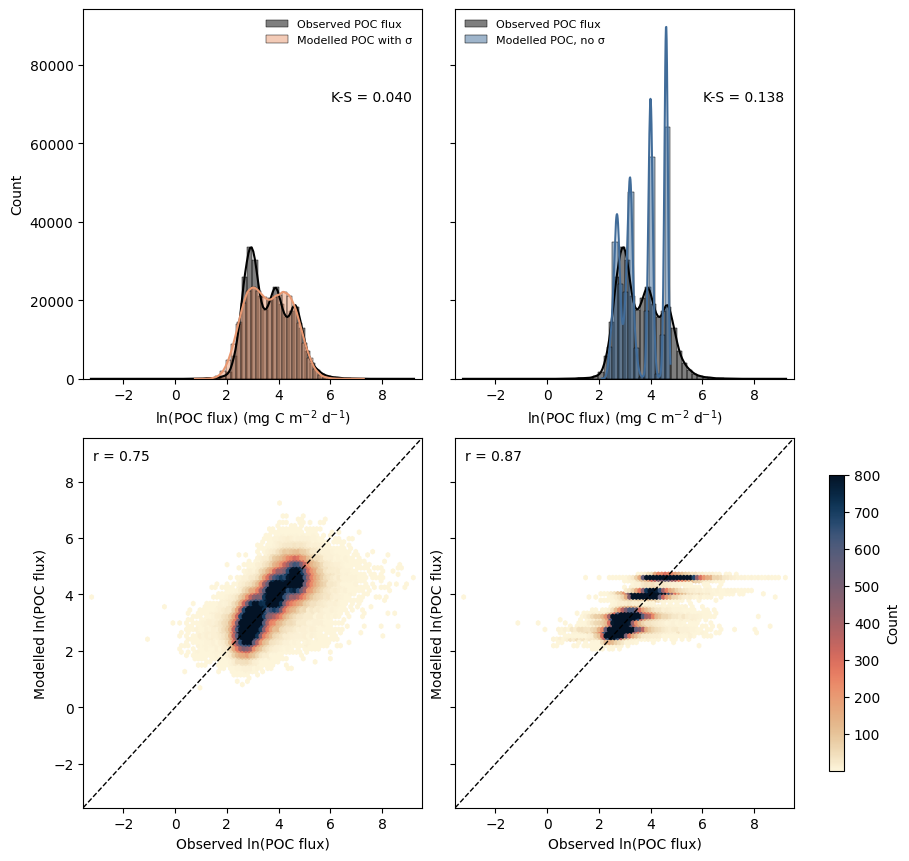

In [4]:
# Figure 2 of Edwards et al.: histograms and density scatter, with sigma and with sigma = 0
fig, ax = plt.subplots(2, 2, figsize=(9, 8.5), sharex="row", sharey="row", constrained_layout=True)
lim = (y.min() - .3, y.max() + .3)

for j, (gen, color, label, stat, corr) in enumerate(((y_model, "#e99871", "Modelled POC with σ", ks, r),
                                                     (mu, "#416c99", "Modelled POC, no σ", ks0, r0))):
    sns.histplot(x=y, binwidth=.2, kde=True, color="black", alpha=.5, label="Observed POC flux", ax=ax[0, j])
    sns.histplot(x=gen, binwidth=.2, kde=True, color=color, alpha=.5, label=label, ax=ax[0, j])
    ax[0, j].set(xlim=lim, xlabel="ln(POC flux) (mg C m$^{-2}$ d$^{-1}$)", ylabel="Count")
    ax[0, j].legend(frameon=False, fontsize=8)
    ax[0, j].text(.97, .75, f"K-S = {stat:.3f}", transform=ax[0, j].transAxes, ha="right")

    hb = ax[1, j].hexbin(y, gen, cmap=cm.lipari_r, mincnt=1, gridsize=100, extent=(*lim, *lim), vmin=1, vmax=800)
    ax[1, j].axline((0, 0), (1, 1), color="black", ls="--", lw=1)
    ax[1, j].set(xlim=lim, ylim=lim, xlabel="Observed ln(POC flux)", ylabel="Modelled ln(POC flux)")
    ax[1, j].text(.03, .94, f"r = {corr:.2f}", transform=ax[1, j].transAxes)
fig.colorbar(hb, ax=ax[1, :], label="Count", shrink=.8)
print("largest hexbin count:", hb.get_array().max())
fig.savefig(PROJ / "figures/step4_pooled_fit.png", dpi=200)
plt.show()

In [5]:
# How well the one model fits each depth; per-depth K-S and r are from step 3
per_depth = {100: (0.048, 0.094), 200: (0.053, 0.275), 500: (0.070, 0.307), 900: (0.075, 0.299)}
rows = []
for depth, (ks_step3, r_step3) in per_depth.items():
    m = clean["depth"].values == depth
    rows.append(dict(depth=depth, n=m.sum(), KS=ks_2samp(y[m], y_model[m]).statistic, KS_step3=ks_step3,
                     r_sigma0=pearsonr(y[m], mu[m])[0], r_sigma0_step3=r_step3,
                     mean_mu_minus_observed=(mu[m] - y[m]).mean(), sigma_median=np.median(sigma[m]),
                     P99_ratio=np.exp(np.percentile(y_model[m], 99) - np.percentile(y[m], 99))))
pd.DataFrame(rows).set_index("depth").round(3)

,n,KS,KS_step3,r_sigma0,r_sigma0_step3,mean_mu_minus_observed,sigma_median,P99_ratio
depth,,,,,,,,
100,75276,0.094,0.048,0.044,0.094,-0.101,0.428,0.664
200,75062,0.160,0.053,0.265,0.275,0.095,0.422,0.917
500,73614,0.178,0.070,0.300,0.307,0.109,0.414,0.835
900,72170,0.143,0.075,0.297,0.299,-0.110,0.404,0.658


In [2]:
# Accuracy of individual values, with and without depth. All predictions are in ln(mg C m-2 d-1)
depth_median = clean.assign(y=y).groupby("depth")["y"].transform("median").values
step3_mu = np.empty(len(y))
for depth, i in clean.groupby("depth").indices.items():
    t, c = standardize(raw["T"][i]), standardize(raw["C"][i])
    b3 = np.load(PROJ / f"fits/draws_{depth}m.npz")["beta"].mean(axis=0)
    step3_mu[i] = np.column_stack([np.ones(len(i)), t, c, t * c]) @ b3 + np.log(12.011)


def accuracy(prediction):
    error = np.abs(y - prediction)
    return {"within 30%": np.mean(np.abs(np.exp(prediction - y) - 1) <= .3),
            "typical error factor": np.exp(np.median(error)),
            "90% of errors below factor": np.exp(np.percentile(error, 90)),
            "r2": 1 - np.sum((y - prediction) ** 2) / np.sum((y - y.mean()) ** 2)}


pd.DataFrame({"one median, no depth": accuracy(np.full(len(y), np.median(y))),
              "one median per depth": accuracy(depth_median),
              "per-depth model (step 3)": accuracy(step3_mu),
              "all-depth model (step 4)": accuracy(mu)}).T.round(3)

,within 30%,typical error factor,90% of errors below factor,r2
"one median, no depth",0.207,1.921,3.703,-0.010
one median per depth,0.631,1.247,1.899,0.750
per-depth model (step 3),0.643,1.235,1.865,0.767
all-depth model (step 4),0.611,1.261,1.904,0.750


**Conclusion: with depth in the model, individual values become much more accurate, but almost all of the gain comes from depth, not from SST or Chl-a.**

| Prediction, all depths together | Within ±30% | Typical error factor | r² |
|---|---:|---:|---:|
| One median, no depth | 20.7% | 1.92 | −0.01 |
| One median per depth | 63.1% | 1.25 | 0.750 |
| Per-depth model (step 3) | 64.3% | 1.24 | 0.767 |
| All-depth model (step 4) | 61.1% | 1.26 | 0.750 |

| Comparison | This fit | Edwards et al. (2026) |
|---|---:|---:|
| Observations | 296,122 | 12,936 |
| K-S with σ / σ = 0 | 0.040 / 0.138 | 0.044 / 0.12 |
| r with σ / σ = 0 | 0.75 / 0.87 | 0.45 / 0.68 |
| SST, Chl-a, depth effect on μ | 0.04, 0.10, −0.73 | 0.39, 0.73, −0.73 |
| SST, Chl-a, depth effect on σ | −0.020, 0.035, −0.014 | −0.12, 0.067, −0.093 |

- The fit converged: R-hat ≤ 1.003, no divergent transitions.
- The depth effect on μ matches Edwards et al., while the SST and Chl-a effects are about one eighth of theirs. These effects are per 1 SD of each predictor in each data set, so the comparison is approximate.
- Our higher r comes from four widely spaced depths. Edwards et al. do not report how much of their r comes from depth alone, so the r values are not directly comparable.
- Each depth fits worse than in step 3: K-S 0.094–0.178 against 0.048–0.075, because ln(depth) misses the depth means by about ±0.1. The per-depth model is the better description of these four depths.
- All numbers are in-sample, and each profile appears up to four times.
- In the density scatter above, the colour scale saturates at 800, while the largest count is 10,202.